# Problem 2: Custom MNIST Digit Recognition & Verification

## Overview
This notebook implements an **MNIST Inference Engine** using pre-trained network weights. It evaluates the network using custom handwritten digit images ($28 \times 28$ grayscale), displaying the image using `imshow` and outputting explicit **Success** or **Fail** recognition messages per the assignment specification; moreover, it classifies handwritten digits stored locally in the `mnist_digits/` directory.

In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def sigmoid(a):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-a))

def softmax(a):
    """Softmax activation function with numerical stability."""
    c = np.max(a)
    exp_a = np.exp(a - c)
    sum_exp_a = np.sum(exp_a)
    return exp_a / sum_exp_a

def init_network(model_file_name='sample_weight.pkl'):
    """Loads network weights and biases from pickle file."""
    # Check if file is in current dir or mnist subfolder
    if not os.path.exists(model_file_name) and os.path.exists(os.path.join('mnist', model_file_name)):
        model_file_name = os.path.join('mnist', model_file_name)
        
    with open(model_file_name, 'rb') as f:
        network = pickle.load(f)
    return network

def predict(network, x):
    """Performs 3-layer forward propagation."""
    W1, W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']

    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)

    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)

    a3 = np.dot(z2, W3) + b3
    y = softmax(a3)

    return y

## Image Preprocessing Pipeline
Custom handwritten images are converted into normalized model inputs through the following pipeline:
1. **Grayscale Conversion:** Convert RGB images to single-channel grayscale (`L` mode).
2. **Resizing:** Standardize resolution to $28 \times 28$ pixels.
3. **Color Inversion Check:** MNIST expects white digits on a black background (0 = black, 255 = white). If the custom image has a light background (mean pixel value $> 127$), pixel values are inverted (`255 - img_array`).
4. **Normalization & Flattening:** Scale pixel intensity values to $[0.0, 1.0]$ and flatten into a 1D vector of length 784.

In [2]:
def preprocess_image(image_path):
    """
    Loads custom handwritten digit image, resizes to 28x28, converts to grayscale,
    and normalizes pixel intensities.
    """
    img = Image.open(image_path).convert("L")  # Convert to grayscale
    img = img.resize((28, 28))                  # Ensure 28x28 dimensions
    img_array = np.array(img)

    # Invert colors if background is bright (white) and digit is dark
    if np.mean(img_array) > 127:
        img_array = 255 - img_array

    # Flatten and normalize to [0, 1]
    flattened_img = img_array.reshape(-1) / 255.0
    return img_array, flattened_img

## Verification & Inference Evaluation
The `test_digit_image` function executes forward propagation on each image and compares the model's highest probability prediction (`np.argmax`) against the expected target digit.

Results follow the explicit assignment formatting requirements:
* **Success:** `Success: Image <filename> is for digit <expected> is recognized as <predicted>.`
* **Fail:** `Fail: Image <filename> is for digit <expected> but the inference result is <predicted>.`

In [3]:
# Initialize network with pre-trained weights
network = init_network('sample_weight.pkl')

def test_digit_image(image_path, expected_digit):
    """
    Displays the image using imshow and outputs explicit Success or Fail message.
    """
    raw_img, processed_img = preprocess_image(image_path)
    
    # Forward propagation inference
    probabilities = predict(network, processed_img)
    predicted_digit = np.argmax(probabilities)
    confidence = np.max(probabilities)

    # Plot image
    plt.figure(figsize=(3, 3))
    plt.imshow(raw_img, cmap='gray')
    plt.axis('off')
    plt.title(f"Target: {expected_digit} | Pred: {predicted_digit}")
    plt.show()

    # Format result output matching assignment requirements
    image_name = os.path.basename(image_path)
    if predicted_digit == expected_digit:
        print(f"Success: Image {image_name} is for digit {expected_digit} is recognized as {predicted_digit}.")
    else:
        print(f"Fail: Image {image_name} is for digit {expected_digit} but the inference result is {predicted_digit}.")
    
    print(f"Confidence: {confidence * 100:.2f}%\n")

Checking directory: c:\ECE5831\HW\HW2\ece-5831-2026-assignments\A_05\mnist_digits
Found: 0_1.png -> Running test...


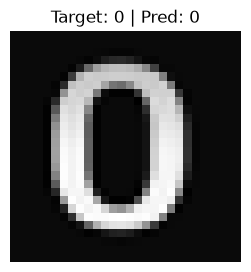

Success: Image 0_1.png is for digit 0 is recognized as 0.
Confidence: 93.40%

Found: 0_2.png -> Running test...


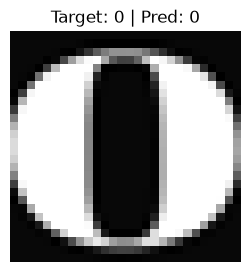

Success: Image 0_2.png is for digit 0 is recognized as 0.
Confidence: 57.99%

Found: 0_3.png -> Running test...


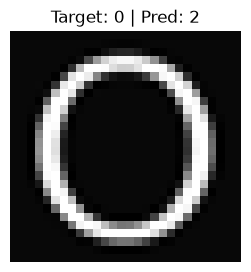

Fail: Image 0_3.png is for digit 0 but the inference result is 2.
Confidence: 51.10%

Found: 0_4.png -> Running test...


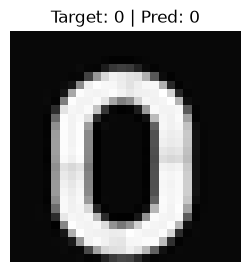

Success: Image 0_4.png is for digit 0 is recognized as 0.
Confidence: 62.75%

Found: 0_5.png -> Running test...


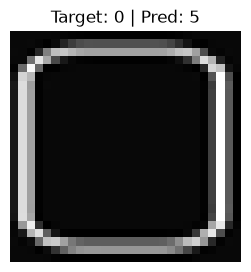

Fail: Image 0_5.png is for digit 0 but the inference result is 5.
Confidence: 47.58%

Found: 1_1.png -> Running test...


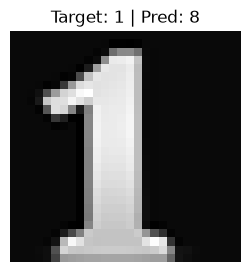

Fail: Image 1_1.png is for digit 1 but the inference result is 8.
Confidence: 83.52%

Found: 1_2.png -> Running test...


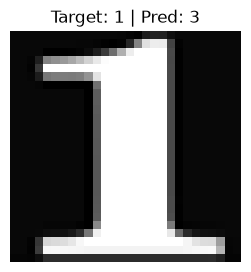

Fail: Image 1_2.png is for digit 1 but the inference result is 3.
Confidence: 94.07%

Found: 1_3.png -> Running test...


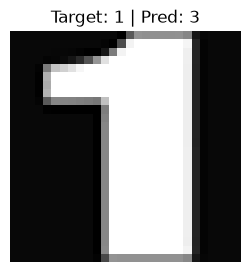

Fail: Image 1_3.png is for digit 1 but the inference result is 3.
Confidence: 98.24%

Found: 1_4.png -> Running test...


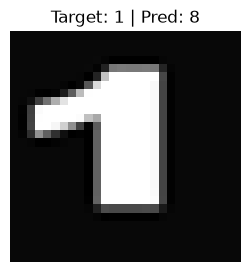

Fail: Image 1_4.png is for digit 1 but the inference result is 8.
Confidence: 87.91%

Found: 1_5.png -> Running test...


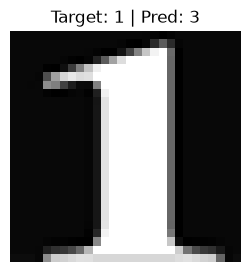

Fail: Image 1_5.png is for digit 1 but the inference result is 3.
Confidence: 95.95%

Found: 2_1.png -> Running test...


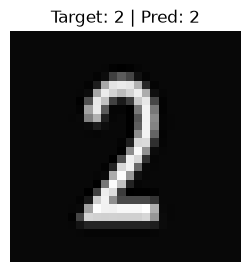

Success: Image 2_1.png is for digit 2 is recognized as 2.
Confidence: 71.88%

Found: 2_2.png -> Running test...


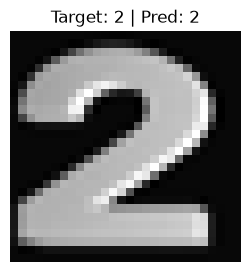

Success: Image 2_2.png is for digit 2 is recognized as 2.
Confidence: 70.01%

Found: 2_3.png -> Running test...


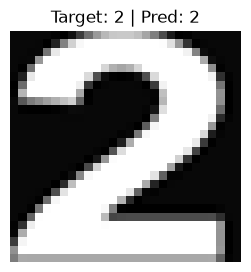

Success: Image 2_3.png is for digit 2 is recognized as 2.
Confidence: 56.55%

Found: 2_4.png -> Running test...


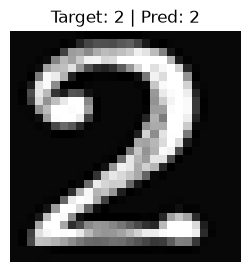

Success: Image 2_4.png is for digit 2 is recognized as 2.
Confidence: 62.64%

Found: 2_5.png -> Running test...


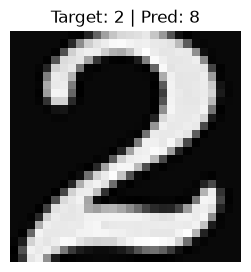

Fail: Image 2_5.png is for digit 2 but the inference result is 8.
Confidence: 76.17%

Found: 3_1.png -> Running test...


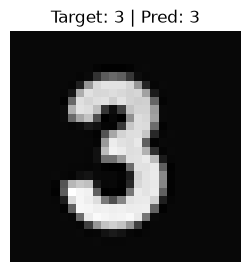

Success: Image 3_1.png is for digit 3 is recognized as 3.
Confidence: 48.17%

Found: 3_2.png -> Running test...


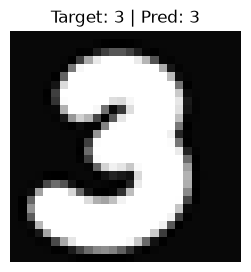

Success: Image 3_2.png is for digit 3 is recognized as 3.
Confidence: 99.84%

Found: 3_3.png -> Running test...


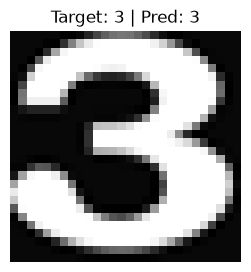

Success: Image 3_3.png is for digit 3 is recognized as 3.
Confidence: 99.46%

Found: 3_4.png -> Running test...


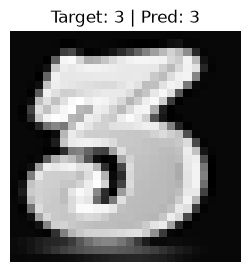

Success: Image 3_4.png is for digit 3 is recognized as 3.
Confidence: 96.80%

Found: 3_5.png -> Running test...


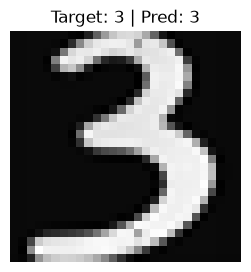

Success: Image 3_5.png is for digit 3 is recognized as 3.
Confidence: 98.99%

Found: 4_1.png -> Running test...


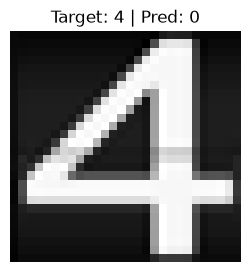

Fail: Image 4_1.png is for digit 4 but the inference result is 0.
Confidence: 86.60%

Found: 4_2.png -> Running test...


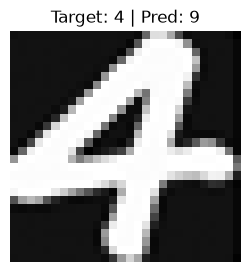

Fail: Image 4_2.png is for digit 4 but the inference result is 9.
Confidence: 39.77%

Found: 4_3.png -> Running test...


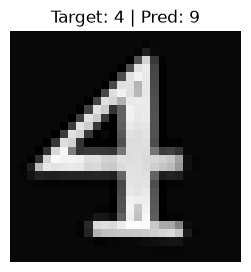

Fail: Image 4_3.png is for digit 4 but the inference result is 9.
Confidence: 56.51%

Found: 4_4.png -> Running test...


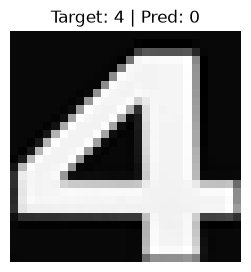

Fail: Image 4_4.png is for digit 4 but the inference result is 0.
Confidence: 91.29%

Found: 4_5.png -> Running test...


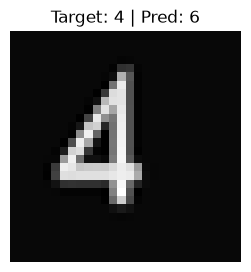

Fail: Image 4_5.png is for digit 4 but the inference result is 6.
Confidence: 61.10%

Found: 5_1.png -> Running test...


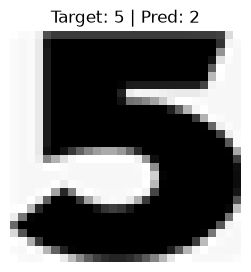

Fail: Image 5_1.png is for digit 5 but the inference result is 2.
Confidence: 74.38%

Found: 5_2.png -> Running test...


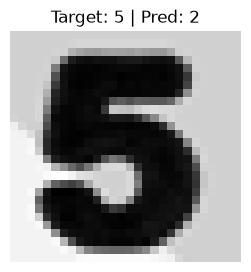

Fail: Image 5_2.png is for digit 5 but the inference result is 2.
Confidence: 90.78%

Found: 5_3.png -> Running test...


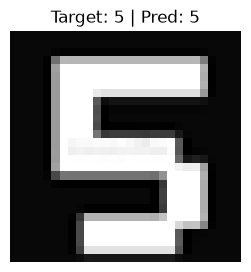

Success: Image 5_3.png is for digit 5 is recognized as 5.
Confidence: 54.57%

Found: 5_4.png -> Running test...


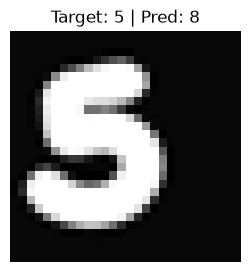

Fail: Image 5_4.png is for digit 5 but the inference result is 8.
Confidence: 76.95%

Found: 5_5.png -> Running test...


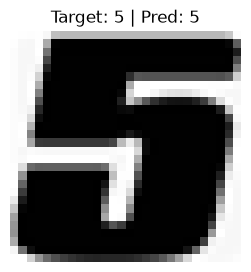

Success: Image 5_5.png is for digit 5 is recognized as 5.
Confidence: 43.66%

Found: 6_1.png -> Running test...


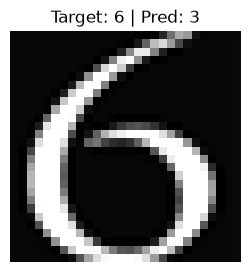

Fail: Image 6_1.png is for digit 6 but the inference result is 3.
Confidence: 97.25%

Found: 6_2.png -> Running test...


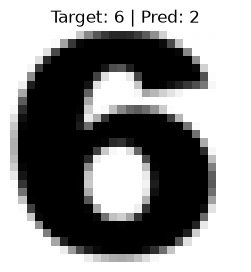

Fail: Image 6_2.png is for digit 6 but the inference result is 2.
Confidence: 70.54%

Found: 6_3.png -> Running test...


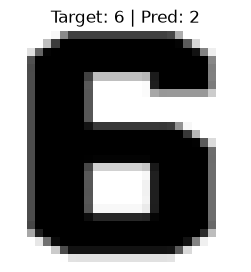

Fail: Image 6_3.png is for digit 6 but the inference result is 2.
Confidence: 60.62%

Found: 6_4.png -> Running test...


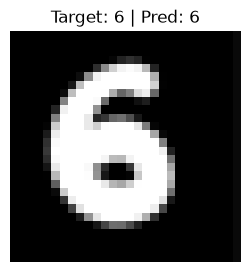

Success: Image 6_4.png is for digit 6 is recognized as 6.
Confidence: 80.62%

Found: 6_5.png -> Running test...


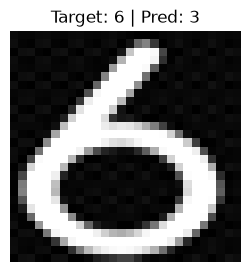

Fail: Image 6_5.png is for digit 6 but the inference result is 3.
Confidence: 61.22%

Found: 7_1.png -> Running test...


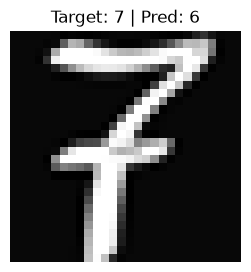

Fail: Image 7_1.png is for digit 7 but the inference result is 6.
Confidence: 82.51%

Found: 7_2.png -> Running test...


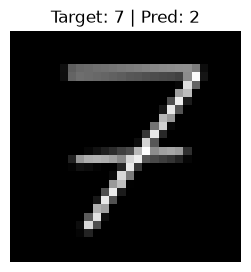

Fail: Image 7_2.png is for digit 7 but the inference result is 2.
Confidence: 39.57%

Found: 7_3.png -> Running test...


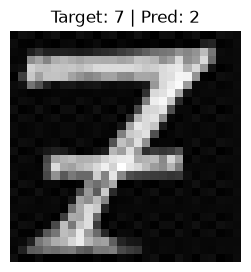

Fail: Image 7_3.png is for digit 7 but the inference result is 2.
Confidence: 73.70%

Found: 7_4.png -> Running test...


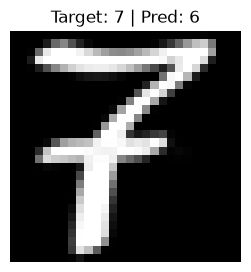

Fail: Image 7_4.png is for digit 7 but the inference result is 6.
Confidence: 95.14%

Found: 7_5.png -> Running test...


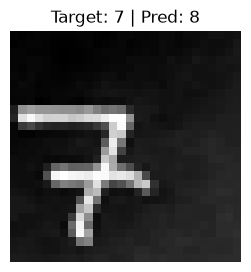

Fail: Image 7_5.png is for digit 7 but the inference result is 8.
Confidence: 70.67%

Found: 8_1.png -> Running test...


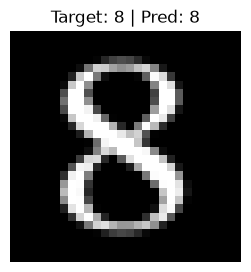

Success: Image 8_1.png is for digit 8 is recognized as 8.
Confidence: 77.20%

Found: 8_2.png -> Running test...


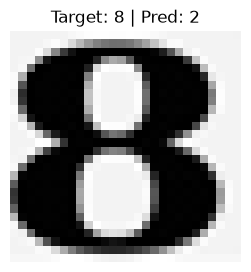

Fail: Image 8_2.png is for digit 8 but the inference result is 2.
Confidence: 80.41%

Found: 8_3.png -> Running test...


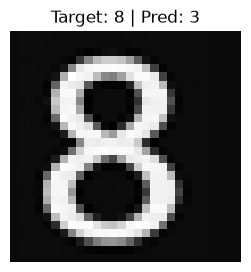

Fail: Image 8_3.png is for digit 8 but the inference result is 3.
Confidence: 98.37%

Found: 8_4.png -> Running test...


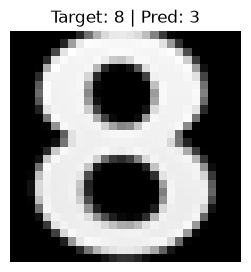

Fail: Image 8_4.png is for digit 8 but the inference result is 3.
Confidence: 95.92%

Found: 8_5.png -> Running test...


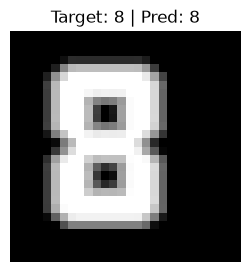

Success: Image 8_5.png is for digit 8 is recognized as 8.
Confidence: 41.98%

Found: 9_1.png -> Running test...


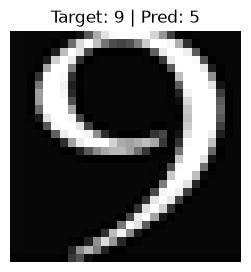

Fail: Image 9_1.png is for digit 9 but the inference result is 5.
Confidence: 97.43%

Found: 9_2.png -> Running test...


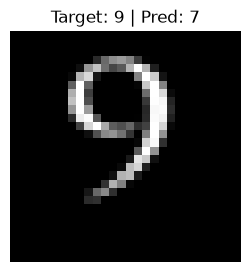

Fail: Image 9_2.png is for digit 9 but the inference result is 7.
Confidence: 79.84%

Found: 9_3.png -> Running test...


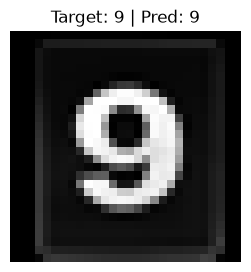

Success: Image 9_3.png is for digit 9 is recognized as 9.
Confidence: 67.64%

Found: 9_4.png -> Running test...


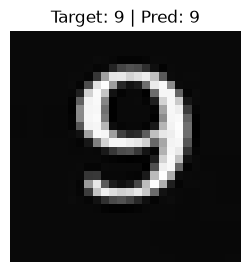

Success: Image 9_4.png is for digit 9 is recognized as 9.
Confidence: 40.45%

Found: 9_5.png -> Running test...


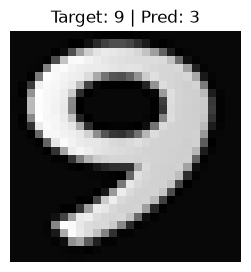

Fail: Image 9_5.png is for digit 9 but the inference result is 3.
Confidence: 46.86%


Evaluation complete. Total evaluated images found: 50 / 50


In [4]:
# Run verification over all custom handwritten test images stored in mnist_digits/
import os

digits_dir = "mnist_digits"
print(f"Checking directory: {os.path.abspath(digits_dir)}")
found_count = 0

for digit in range(10):
    for version in range(1, 6):
        file_name = f"{digit}_{version}.png"
        file_path = os.path.join(digits_dir, file_name)
        
        if os.path.exists(file_path):
            found_count += 1
            print(f"Found: {file_name} -> Running test...")
            test_digit_image(file_path, expected_digit=digit)
        else:
            # Fallback check if images are in current directory
            if os.path.exists(file_name):
                found_count += 1
                print(f"Found in root: {file_name} -> Running test...")
                test_digit_image(file_name, expected_digit=digit)

print(f"\nEvaluation complete. Total evaluated images found: {found_count} / 50")